In [12]:
import pandas as pd
import numpy as np

# Use one shared seed so every group member can reproduce the same split.
RANDOM_STATE = 313

# Load both years and combine them into one DataFrame
df_2023 = pd.read_excel('ttc-subway-delay-data-2023.xlsx')
df_2024 = pd.read_excel('ttc-subway-delay-data-2024.xlsx')
df = pd.concat([df_2023, df_2024], ignore_index=True)

# Inspect dataset size, column names, and data types
print(f"Dataset Size: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.info())
display(df.head())

Dataset Size: 49416 rows and 10 columns
<class 'pandas.DataFrame'>
RangeIndex: 49416 entries, 0 to 49415
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       49416 non-null  datetime64[us]
 1   Time       49416 non-null  str           
 2   Day        49416 non-null  str           
 3   Station    49416 non-null  str           
 4   Code       49416 non-null  str           
 5   Min Delay  49416 non-null  int64         
 6   Min Gap    49416 non-null  int64         
 7   Bound      31370 non-null  str           
 8   Line       49324 non-null  str           
 9   Vehicle    49416 non-null  int64         
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 5.5 MB


None

,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,2023-01-01,02:22,Sunday,MUSEUM STATION,MUPAA,3,9,S,YU,5931
1,2023-01-01,02:30,Sunday,KIPLING STATION,MUIS,0,0,E,BD,5341
2,2023-01-01,02:33,Sunday,WARDEN STATION,SUO,0,0,W,BD,0
3,2023-01-01,03:17,Sunday,KEELE STATION,MUIS,0,0,NaN,BD,0
4,2023-01-01,07:16,Sunday,BATHURST STATION,MUIS,0,0,NaN,BD,0


## Feature Categorization

Feature categorization means grouping columns according to the kind of information they contain and how they will be used in the analysis.

| Category | Features | Explanation |
|---|---|---|
| Temporal | `Date`, `Time`, `Day` | Describe when the subway delay occurred. |
| Categorical | `Station`, `Code`, `Bound`, `Line` | Describe groups or labels, such as the station, delay type, direction, and subway line. |
| Numerical | `Min Delay`, `Min Gap` | Contain numerical measurements of delay and service-gap duration in minutes. |
| Identifier-like | `Vehicle` | Identifies a subway vehicle. A value of `0` may indicate that a vehicle was unavailable or not applicable. |
| Target variable | `Min Delay` | The regression target because we want to predict the exact delay duration. |
| Derived target variable | `Prolonged_Disruption` | The classification target, created later as 1 when `Min Delay` is greater than 15 minutes and 0 otherwise. |

### Why categorize the features?

Categorizing features helps us choose the correct EDA and preprocessing methods.

- Numerical features can be summarized using means, medians, standard deviations, and histograms.
- Categorical features can be examined using frequency counts and bar charts.
- Temporal features can be used to investigate patterns by hour, day, weekday, or month.
- Identifier-like features may need special treatment because their numbers are labels, not measurements.
- Target variables must be analyzed separately because they are the outcomes that future machine-learning models will predict.

In [13]:
# Categorize the original features by their role and data type
temporal_features = [
    "Date",
    "Time",
    "Day"
]

categorical_features = [
    "Station",
    "Code",
    "Bound",
    "Line"
]

numeric_features = [
    "Min Delay",
    "Min Gap"
]

identifier_features = [
    "Vehicle"
]

target_variables = [
    "Min Delay",
    "Prolonged_Disruption"
]

feature_categories = {
    "Temporal": temporal_features,
    "Categorical": categorical_features,
    "Numerical": numeric_features,
    "Identifier-like": identifier_features,
    "Target variables": target_variables
}

for category, features in feature_categories.items():
    print(f"{category}: {features}")

Temporal: ['Date', 'Time', 'Day']
Categorical: ['Station', 'Code', 'Bound', 'Line']
Numerical: ['Min Delay', 'Min Gap']
Identifier-like: ['Vehicle']
Target variables: ['Min Delay', 'Prolonged_Disruption']


## Creating the Training and Test Sets

Before building a machine-learning model, we divide the data into two parts:

- **Training set (80%)**: used to teach the model patterns in the data.
- **Test set (20%)**: kept separate until the end and used to evaluate how well the model works on unseen records.

We use stratified sampling for this split. Stratification means that the training and test sets keep similar proportions of important groups from the full dataset. Here, the stratification groups combine:

1. Whether the delay is prolonged (`Min Delay > 15` minutes),
2. The season in which the event occurred, and
3. Whether the event occurred on a weekend.

This helps prevent the test set from accidentally containing too many records from one season or too few prolonged disruptions. The split is random but reproducible because we use `random_state=313`.

For this assignment, a random stratified split is suitable because we are asked to use an 80/20 split. For a later real-world deployment study, we could also test a chronological split, where older records train the model and newer records test it.

In [14]:
from sklearn.model_selection import train_test_split

# Create the classification target from the regression target.
df["Prolonged_Disruption"] = (df["Min Delay"] > 15).astype(int)

# Create temporal features used only to balance the split.
df["Month"] = df["Date"].dt.month
# January, February, and December are assigned to Winter.
df["Season"] = df["Month"].map({
    1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall",
    11: "Fall", 12: "Winter"
})
df["Is_Weekend"] = df["Day"].isin(["Saturday", "Sunday"]).astype(int)

# Combine the important groups into one stratification label.
df["stratify_group"] = (
    df["Prolonged_Disruption"].astype(str)
    + "_" + df["Season"]
    + "_" + df["Is_Weekend"].astype(str)
)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["stratify_group"]
)

# The helper column is no longer needed after the split.
train_df = train_df.drop(columns="stratify_group")
test_df = test_df.drop(columns="stratify_group")

print(f"Training set: {train_df.shape[0]:,} rows")
print(f"Test set: {test_df.shape[0]:,} rows")


Training set: 39,532 rows
Test set: 9,884 rows


The original combined dataset remains in `df`, while `train_df` and `test_df` contain the two subsets. The `Month`, `Season`, `Is_Weekend`, and `Prolonged_Disruption` columns are retained because they will be useful in later EDA and modeling discussions. The original `Min Delay` column should not be used as an input feature when predicting `Prolonged_Disruption`, because the classification target was calculated directly from it.

## Missing-Value and Data-Quality Assessment

A missing value means that no value was recorded for a field. Missingness is not automatically an error: for example, a delay may not have a recorded direction if the direction was unavailable or not applicable. We therefore measure missing values before deciding whether to remove, impute, or keep them.

We perform this assessment before imputation. Imputation means replacing missing values with estimated values, such as a median for a numerical column or the most common category for a categorical column. Those replacements should eventually be learned from the training set only, so information from the test set does not influence the model.

The initial audit showed that approximately 36.52% of `Bound` values are missing, while only about 0.19% of `Line` values are missing. The remaining original columns have no missing values. We will investigate the meaning of missing `Bound` values before selecting a treatment.

In [15]:
# Count and calculate the percentage of missing values in each column.
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
missing_summary = missing_summary.sort_values(
    by="Missing Percentage", ascending=False
)
display(missing_summary)

# Check the observed date range and whether any dates fall outside the project scope.
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Dates outside 2023-2024: {((df['Date'] < '2023-01-01') | (df['Date'] > '2024-12-31')).sum()}")

# Check for exact duplicate rows and negative numeric values.
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print("Negative numeric values:")
display((df[["Min Delay", "Min Gap", "Vehicle"]] < 0).sum())

,Missing Count,Missing Percentage
Bound,18046,36.52
Line,92,0.19
Date,0,0.00
Time,0,0.00
Day,0,0.00
Station,0,0.00
Code,0,0.00
Min Delay,0,0.00
Min Gap,0,0.00
Vehicle,0,0.00


Date range: 2023-01-01 to 2024-12-31
Dates outside 2023-2024: 0
Exact duplicate rows: 23
Negative numeric values:


Min Delay    0
Min Gap      0
Vehicle      0
dtype: int64

### Initial data-quality decisions

- No date correction is needed because all records are within the selected 2023–2024 range.
- No negative values were found in `Min Delay`, `Min Gap`, or `Vehicle`.
- The 23 exact duplicate rows should be reviewed and removed only if they represent duplicate reports rather than legitimate repeated events.
- Missing `Line` values are rare and can be investigated separately.
- Missing `Bound` values are common. We should not fill them with a guessed direction. For now, we will preserve them and decide later whether to label them as `Unknown` or exclude the column from a particular model.

## Investigating Missing Direction Values

The `Bound` column contains 18,046 missing values, representing approximately 36.52% of the dataset. Instead of immediately imputing these values, we compare records with a recorded direction against records with a missing direction.

This helps determine whether the missingness is random or associated with specific delay codes, subway lines, delay durations, or types of operational events.

Because direction may not be applicable to every incident, replacing missing values with a guessed direction could introduce incorrect information. We will therefore examine the missingness pattern before selecting a final preprocessing strategy.

In [16]:
# Create a flag identifying whether Bound is missing.
df["Bound_Missing"] = df["Bound"].isna()

# Compare the number of records with recorded and missing directions.
bound_missing_counts = (
    df["Bound_Missing"]
    .value_counts()
    .rename({False: "Bound recorded", True: "Bound missing"})
)

display(bound_missing_counts)

# Compare delay statistics for the two groups.
bound_delay_summary = (
    df.groupby("Bound_Missing")["Min Delay"]
    .agg(["count", "mean", "median", "max"])
    .rename(index={False: "Bound recorded", True: "Bound missing"})
    .round(2)
)

display(bound_delay_summary)

# Compare the percentage of prolonged disruptions.
bound_prolonged_rate = (
    df.groupby("Bound_Missing")["Prolonged_Disruption"]
    .mean()
    .mul(100)
    .round(2)
    .rename(index={False: "Bound recorded", True: "Bound missing"})
    .to_frame("Prolonged disruption percentage")
)

display(bound_prolonged_rate)

Bound_Missing
Bound recorded    31370
Bound missing     18046
Name: count, dtype: int64

,count,mean,median,max
Bound_Missing,,,,
Bound recorded,31370,4.48,3.0,716
Bound missing,18046,0.10,0.0,56


,Prolonged disruption percentage
Bound_Missing,
Bound recorded,4.97
Bound missing,0.13


In [17]:
# Identify delay codes with the highest missing-Bound rates.
code_bound_summary = (
    df.groupby("Code")
    .agg(
        Records=("Code", "size"),
        Missing_Bound_Rate=("Bound_Missing", "mean"),
        Average_Delay=("Min Delay", "mean")
    )
)

# Avoid interpreting rates from codes with very few records.
code_bound_summary = (
    code_bound_summary[code_bound_summary["Records"] >= 50]
    .sort_values("Missing_Bound_Rate", ascending=False)
)

code_bound_summary["Missing_Bound_Rate"] = (
    code_bound_summary["Missing_Bound_Rate"] * 100
).round(2)

display(code_bound_summary.head(15))

,Records,Missing_Bound_Rate,Average_Delay
Code,,,
MUNCA,1226,98.53,0.000000
TUNCA,168,95.83,0.000000
PUMEL,1519,93.09,0.023041
MUGD,63,92.06,0.000000
PUMST,597,87.44,0.006700
PUMO,238,84.87,0.306723
MRO,249,79.92,0.674699
MUIS,5393,78.55,0.072687
MUIE,308,77.92,0.301948


## Visualizing the Missing-Bound Pattern

Tables show the exact values, while graphs make differences between groups easier to see. The first chart displays the percentage of missing `Bound` values for the 15 delay codes with the highest rates, using only codes with at least 50 records. The second chart compares the percentage of prolonged disruptions when `Bound` is recorded versus missing.

If missingness were unrelated to the type of event, the delay-code bars would be relatively similar and the two prolonged-disruption rates would be close. Large differences indicate that missing `Bound` values are associated with particular incident patterns. This does not prove the cause of missingness, but it is evidence that the missingness is not uniformly distributed across the dataset.

The graphs support keeping missing directions as missing during EDA rather than replacing them with a guessed compass direction. A later modeling pipeline can represent them as `Unknown` if a complete categorical feature is required.

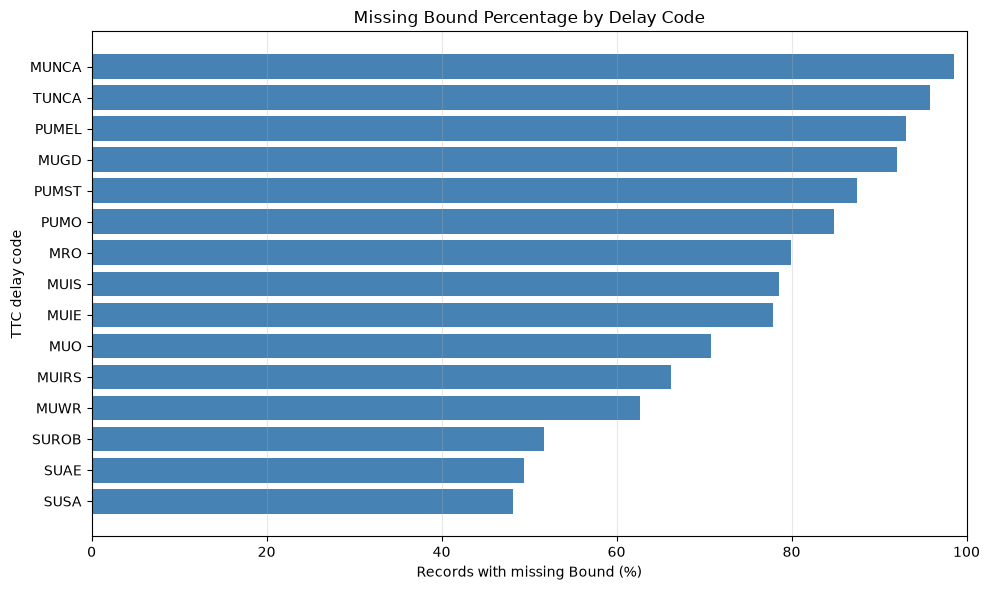

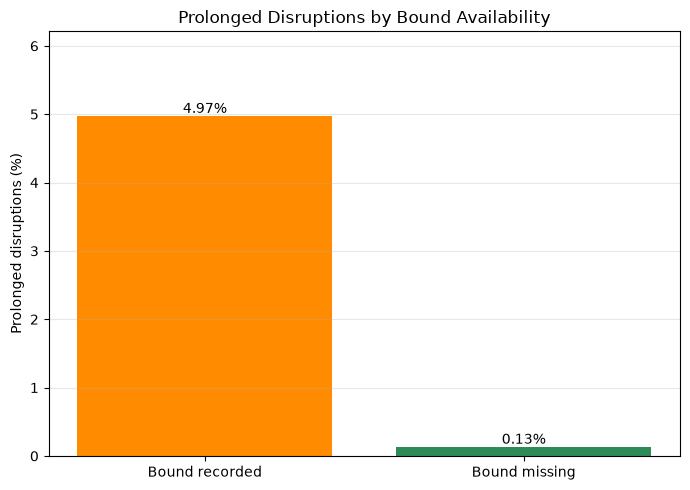

In [18]:
import matplotlib.pyplot as plt

# Plot missing-Bound rates for the most common, high-missingness codes.
plot_data = code_bound_summary.head(15).sort_values("Missing_Bound_Rate")
plt.figure(figsize=(10, 6))
plt.barh(plot_data.index, plot_data["Missing_Bound_Rate"], color="steelblue")
plt.xlabel("Records with missing Bound (%)")
plt.ylabel("TTC delay code")
plt.title("Missing Bound Percentage by Delay Code")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare prolonged-disruption rates for missing and recorded directions.
rate_plot = bound_prolonged_rate["Prolonged disruption percentage"]
plt.figure(figsize=(7, 5))
bars = plt.bar(rate_plot.index, rate_plot.values, color=["darkorange", "seagreen"])
plt.ylabel("Prolonged disruptions (%)")
plt.title("Prolonged Disruptions by Bound Availability")
plt.ylim(0, max(rate_plot.max() * 1.25, 1))
plt.grid(axis="y", alpha=0.3)
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()